# 03 — Forecast evaluation protocol

## Problem
Random row splits leak future time patterns into training and produce misleading traffic forecasts.

## Solution
Keep the data chronological: 70% training, 10% reserved validation, and the final 20% test. Evaluate five-minute speed forecasts at 5, 15, 30, and 60 minutes with MAE, RMSE, and MAPE over observed nonzero targets.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
FIG = ROOT / 'results' / 'figures'
METRICS = ROOT / 'results' / 'metrics'
FIG.mkdir(parents=True, exist_ok=True)
METRICS.mkdir(parents=True, exist_ok=True)
timestamps = pd.read_csv(ROOT / 'data' / 'METR-LA.csv', usecols=[0], parse_dates=[0]).iloc[:, 0]
train_end = int(len(timestamps) * .70)
validation_end = int(len(timestamps) * .80)
rules = pd.DataFrame([
    ['Training', 'First 70% of timestamps', str(timestamps.iloc[0]), str(timestamps.iloc[train_end - 1])],
    ['Validation', 'Next 10%, reserved for tuning', str(timestamps.iloc[train_end]), str(timestamps.iloc[validation_end - 1])],
    ['Test', 'Final 20%, held out', str(timestamps.iloc[validation_end]), str(timestamps.iloc[-1])],
    ['Features', 'Speed at t, lags 1/2/5, cyclic time and weekday', '', ''],
    ['Forecast horizons', '5, 15, 30, 60 minutes (1, 3, 6, 12 steps)', '', ''],
    ['Missing values', 'Zero speed sentinel; causal forward-fill for features', '', ''],
    ['Metrics', 'MAE, RMSE, MAPE on valid observed test speeds', '', '']
], columns=['rule', 'choice', 'start', 'end'])
display(rules)
rules.to_csv(METRICS / 'evaluation_protocol.csv', index=False)
print(f'{len(timestamps):,} METR-LA timestamps | train end {train_end:,} | test begins {validation_end:,}')

,rule,choice,start,end
0,Training,First 70% of timestamps,2012-03-01 00:00:00,2012-05-23 07:05:00
1,Validation,"Next 10%, reserved for tuning",2012-05-23 07:10:00,2012-06-04 04:40:00
2,Test,"Final 20%, held out",2012-06-04 04:45:00,2012-06-27 23:55:00
3,Features,"Speed at t, lags 1/2/5, cyclic time and weekday",,
4,Forecast horizons,"5, 15, 30, 60 minutes (1, 3, 6, 12 steps)",,
5,Missing values,Zero speed sentinel; causal forward-fill for f...,,
6,Metrics,"MAE, RMSE, MAPE on valid observed test speeds",,


34,272 METR-LA timestamps | train end 23,990 | test begins 27,417


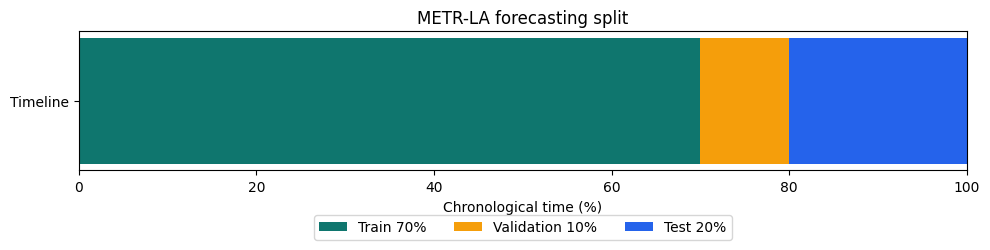

Saved results/figures/10_evaluation_protocol.png


In [2]:
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.barh(['Timeline'], [70], color='#0f766e', label='Train 70%')
ax.barh(['Timeline'], [10], left=[70], color='#f59e0b', label='Validation 10%')
ax.barh(['Timeline'], [20], left=[80], color='#2563eb', label='Test 20%')
ax.set(xlim=(0, 100), xlabel='Chronological time (%)', title='METR-LA forecasting split')
ax.legend(ncol=3, loc='lower center', bbox_to_anchor=(.5, -.55))
fig.tight_layout()
fig.savefig(FIG / '10_evaluation_protocol.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)
print('Saved results/figures/10_evaluation_protocol.png')